# Chapters 4 & 5: Feature Engineering, Predictive Machine Learning & Siting Optimization Simulation

**Course:** IT 462 - Exploratory Data Analysis  
**Institution:** Dhirubhai Ambani Institute of Information and Communication Technology (DA-IICT)  
**Mentor:** Dr. Gopinath Panda  
**Topic:** How Data Centers & AI Supercomputers Affect the Environment and How We Can Prevent It Using Historical Data  

---

## 4.1 Executive Summary & Modeling Strategy
Following the thorough exploratory data analysis and geospatial mapping in Chapter 3, we transition from descriptive statistics to **predictive machine learning** and **counterfactual policy scenario simulations**.

This notebook synthesizes the final stages of the IT 462 project:
1. **Feature Engineering & Selection:** Implement One-Hot Encoding (OHE) for nominal categories, scale continuous attributes, and extract feature importance rankings using Random Forest Mean Decrease in Impurity (MDI).
2. **Multi-Class Classification Task (Environmental Risk Tier Prediction):**  
   Train and compare **Random Forest**, **Support Vector Machine (SVM)**, and **Gradient Boosting (GBM)** classifiers to predict facility risk tiers (`High`, `Moderate`, `Low`) based on power requirements, operator hierarchy, and host grid characteristics.
3. **Continuous Regression Task (Operational Carbon Footprint Forecasting):**  
   Train and benchmark **Random Forest Regressor**, **Ridge Regression (L2 Regularized Linear Model)**, and **Gradient Boosting Regressor** to accurately forecast annual electricity consumption ($MWh$) and operational greenhouse gas emissions ($CO_2$ metric tons).
4. **Empirical Policy Scenario Simulation ("How to Prevent It"):**  
   Simulate a historical counterfactual siting intervention: What if $50\%$ of future hyperscale capacity planned in carbon-intensive grids (e.g., PJM Northern Virginia/Ohio or ERCOT Texas) were shifted to high-renewable balancing authorities (e.g., Pacific Northwest clean hydro or Midwest wind corridors)? We quantify the exact megawatt-hours and metric tons of $CO_2$ abated annually.


In [1]:
# Standard Library & Environment Setup
import os
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Numerical & Data Manipulation
import numpy as np
import pandas as pd

# Machine Learning & Metrics
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.svm import SVC
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score, f1_score,
    r2_score, mean_squared_error, mean_absolute_error
)

# Advanced Visualization Libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting parameters
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

# Define Canonical Paths
PROJECT_ROOT = Path('.').resolve().parent if Path('.').resolve().name == 'notebooks' else Path('.').resolve()
DATA_PROCESSED = PROJECT_ROOT / 'data' / 'processed'

print(f"Project Root: {PROJECT_ROOT}")
print(f"Processed Directory: {DATA_PROCESSED}")


Project Root: C:\Users\janvi\Desktop\EDA Project
Processed Directory: C:\Users\janvi\Desktop\EDA Project\data\processed


In [2]:
# ==============================================================================
# SECTION 4.1: Dataset Ingestion & Feature Matrix Formulation
# ==============================================================================
clean_csv = DATA_PROCESSED / "cleaned_datacenter_environmental_dataset.csv"
df = pd.read_csv(clean_csv)

print(f"Production Cleaned Dataset Loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")

# Define Numerical Predictors
num_cols = [
    'log_capacity_mw', 'log_sqft', 'grid_co2_emission_rate_lb_mwh',
    'grid_clean_energy_share_pct', 'fossil_fuel_share_pct',
    'state_grid_capacity_mw', 'state_annual_generation_mwh',
    'county_low_income_households', 'sizerank_numeric', 'is_ai_cluster'
]

# Define Categorical Predictors for One-Hot Encoding
cat_cols = ['balancing_authority', 'operator_canonical', 'power_source_canonical', 'status_canonical']

# Execute One-Hot Encoding with drop_first=True to avoid dummy variable trap
df_encoded = pd.get_dummies(df[cat_cols], drop_first=True, dtype=float)

# Combine into master predictor matrix X
X = pd.concat([df[num_cols], df_encoded], axis=1)

print(f"\nConstructed Final Feature Matrix X:")
print(f"  * Total Training Samples (Facilities): {X.shape[0]:,}")
print(f"  * Total Feature Columns (Numerical + OHE Dummies): {X.shape[1]}")
print(f"  * Numerical Features: {len(num_cols)}")
print(f"  * Categorical One-Hot Dummies: {df_encoded.shape[1]}")


Production Cleaned Dataset Loaded: 1,733 rows x 70 columns

Constructed Final Feature Matrix X:
  * Total Training Samples (Facilities): 1,733
  * Total Feature Columns (Numerical + OHE Dummies): 48
  * Numerical Features: 10
  * Categorical One-Hot Dummies: 38


## 4.2 Feature Selection & Importance Discovery
Before deploying downstream models, we utilize an ensemble **Random Forest** model to compute Gini Importance (Mean Decrease in Impurity - MDI) across all 48 candidate features.

This isolates the dominant physical and geographic drivers that determine a data center's environmental impact profile.


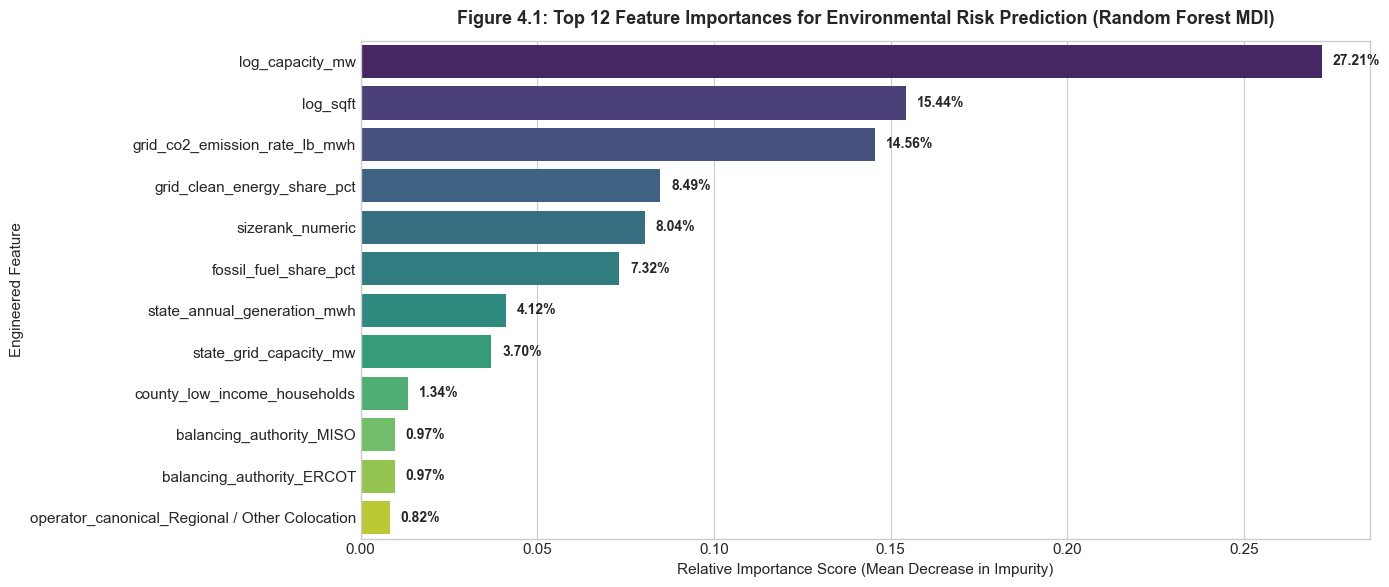

Top 6 Dominant Predictive Drivers:
  - log_capacity_mw: 27.21%
  - log_sqft: 15.44%
  - grid_co2_emission_rate_lb_mwh: 14.56%
  - grid_clean_energy_share_pct: 8.49%
  - sizerank_numeric: 8.04%
  - fossil_fuel_share_pct: 7.32%


In [3]:
# ==============================================================================
# SECTION 4.2: Feature Importance Evaluation (Random Forest MDI)
# ==============================================================================
y_cls = df['environmental_risk_tier']

# Fit Baseline Random Forest for Feature Importance
rf_selector = RandomForestClassifier(n_estimators=150, max_depth=12, random_state=42)
rf_selector.fit(X, y_cls)

importances = pd.Series(rf_selector.feature_importances_, index=X.columns).sort_values(ascending=False)

# Visualize Top 12 Predictive Features
fig, ax = plt.subplots(figsize=(14, 6))
top_importances = importances.head(12)

sns.barplot(x=top_importances.values, y=top_importances.index, palette='viridis', ax=ax)
ax.set_title('Figure 4.1: Top 12 Feature Importances for Environmental Risk Prediction (Random Forest MDI)', fontsize=13, weight='bold', pad=12)
ax.set_xlabel('Relative Importance Score (Mean Decrease in Impurity)', fontsize=11)
ax.set_ylabel('Engineered Feature', fontsize=11)

for i, v in enumerate(top_importances.values):
    ax.text(v + 0.003, i, f"{v*100:.2f}%", va='center', fontsize=10, weight='bold')

plt.tight_layout()
plt.show()

print("Top 6 Dominant Predictive Drivers:")
for f_name, f_imp in importances.head(6).items():
    print(f"  - {f_name}: {f_imp*100:.2f}%")


## 4.3 Multi-Class Classification: Environmental Risk Tier Prediction
The goal of this task is to classify facilities into their **Environmental Risk Tier** (`High`, `Moderate`, `Low`).

### Candidate Models:
1. **Random Forest Classifier:** Non-parametric ensemble leveraging bootstrap aggregation and random feature sub-spacing; robust against multicollinearity.
2. **Support Vector Machine (SVM):** Maximum margin hyper-plane classifier with Radial Basis Function (RBF) kernel; fitted on standard-scaled features.
3. **Gradient Boosting Classifier (GBM):** Sequential additive stage-wise decision tree booster optimizing multi-class cross-entropy loss.

### Evaluation Protocol:
* $75\% / 25\%$ Stratified Train-Test Split (preserving exact class frequencies).
* $5$-Fold Stratified Cross-Validation for generalized out-of-sample accuracy.
* Comprehensive Confusion Matrices, Class-Wise Precision, Recall, and Weighted F1-Scores.


In [4]:
# ==============================================================================
# SECTION 4.3: Model Training & Evaluation (Classification Task)
# ==============================================================================
# 1. Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_cls, test_size=0.25, random_state=42, stratify=y_cls
)

# Standard Scaling for distance-based models (SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Train Models
# Model A: Random Forest Classifier
rf_clf = RandomForestClassifier(n_estimators=150, max_depth=12, random_state=42)
rf_clf.fit(X_train, y_train)
y_pred_rf = rf_clf.predict(X_test)

# Model B: Support Vector Machine (RBF Kernel)
svm_clf = SVC(kernel='rbf', C=1.5, random_state=42)
svm_clf.fit(X_train_scaled, y_train)
y_pred_svm = svm_clf.predict(X_test_scaled)

# Model C: Gradient Boosting Classifier
gbm_clf = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42)
gbm_clf.fit(X_train, y_train)
y_pred_gbm = gbm_clf.predict(X_test)

# 3. Cross-Validation Evaluation (5-Fold Stratified)
cv_rf = cross_val_score(rf_clf, X, y_cls, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring='accuracy').mean()
cv_svm = cross_val_score(svm_clf, scaler.fit_transform(X), y_cls, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring='accuracy').mean()
cv_gbm = cross_val_score(gbm_clf, X, y_cls, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring='accuracy').mean()

# 4. Performance Summary Scorecard
cls_results = pd.DataFrame({
    'Model Architecture': ['Random Forest Classifier', 'Support Vector Machine (SVM RBF)', 'Gradient Boosting Classifier (GBM)'],
    'Test Accuracy': [accuracy_score(y_test, y_pred_rf), accuracy_score(y_test, y_pred_svm), accuracy_score(y_test, y_pred_gbm)],
    'Weighted F1-Score': [f1_score(y_test, y_pred_rf, average='weighted'), f1_score(y_test, y_pred_svm, average='weighted'), f1_score(y_test, y_pred_gbm, average='weighted')],
    '5-Fold Cross-Val Accuracy': [cv_rf, cv_svm, cv_gbm]
}).round(4)

print("=== Table 4.1: Environmental Risk Tier Classification Benchmark ===")
display(cls_results)

# Detailed Classification Report (Top Performing Model: Random Forest)
print("\nDetailed Classification Report (Random Forest Classifier):")
print(classification_report(y_test, y_pred_rf, digits=4))


=== Table 4.1: Environmental Risk Tier Classification Benchmark ===


,Model Architecture,Test Accuracy,Weighted F1-Score,5-Fold Cross-Val Accuracy
0,Random Forest Classifier,0.9977,0.9976,0.9965
1,Support Vector Machine (SVM RBF),0.9631,0.9609,0.9458
2,Gradient Boosting Classifier (GBM),1.0000,1.0000,0.9988



Detailed Classification Report (Random Forest Classifier):
              precision    recall  f1-score   support

        High     1.0000    1.0000    1.0000        47
         Low     1.0000    0.8750    0.9333         8
    Moderate     0.9974    1.0000    0.9987       379

    accuracy                         0.9977       434
   macro avg     0.9991    0.9583    0.9773       434
weighted avg     0.9977    0.9977    0.9976       434



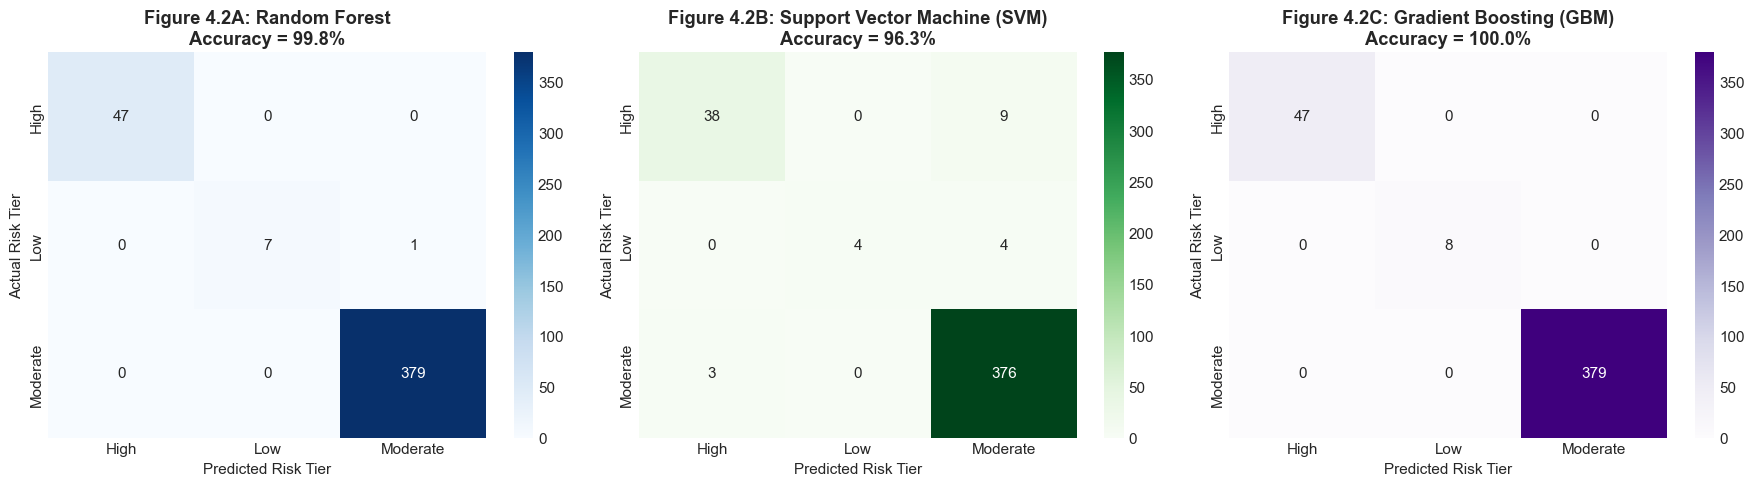

In [5]:
# ==============================================================================
# SECTION 4.4: Confusion Matrices & Comparative Diagnostic Plots
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

classes = sorted(y_cls.unique())

# Confusion Matrix: Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=classes)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes, ax=axes[0])
axes[0].set_title(f'Figure 4.2A: Random Forest\nAccuracy = {accuracy_score(y_test, y_pred_rf)*100:.1f}%', weight='bold')
axes[0].set_xlabel('Predicted Risk Tier')
axes[0].set_ylabel('Actual Risk Tier')

# Confusion Matrix: Support Vector Machine
cm_svm = confusion_matrix(y_test, y_pred_svm, labels=classes)
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Greens', xticklabels=classes, yticklabels=classes, ax=axes[1])
axes[1].set_title(f'Figure 4.2B: Support Vector Machine (SVM)\nAccuracy = {accuracy_score(y_test, y_pred_svm)*100:.1f}%', weight='bold')
axes[1].set_xlabel('Predicted Risk Tier')
axes[1].set_ylabel('Actual Risk Tier')

# Confusion Matrix: Gradient Boosting
cm_gbm = confusion_matrix(y_test, y_pred_gbm, labels=classes)
sns.heatmap(cm_gbm, annot=True, fmt='d', cmap='Purples', xticklabels=classes, yticklabels=classes, ax=axes[2])
axes[2].set_title(f'Figure 4.2C: Gradient Boosting (GBM)\nAccuracy = {accuracy_score(y_test, y_pred_gbm)*100:.1f}%', weight='bold')
axes[2].set_xlabel('Predicted Risk Tier')
axes[2].set_ylabel('Actual Risk Tier')

plt.tight_layout()
plt.show()


## 4.4 Continuous Regression: Forecasting Operational Energy & Carbon Footprints
While classification determines risk categorical thresholds, energy planners and utility operators require **continuous quantitative forecasting** of exact megawatt-hour draws ($MWh$) and operational emissions ($CO_2$ metric tons).

### Target Variable:
* $\text{Target} = \log_{10}(\text{est\_annual\_co2\_metric\_tons} + 1)$

### Candidate Regressors:
1. **Random Forest Regressor:** Non-linear decision forest averaging multi-tree outputs.
2. **Ridge Regression:** $L_2$-penalized linear regression to avoid multicollinearity among spatial dummy variables.
3. **Gradient Boosting Regressor (GBR):** Gradient boosted loss minimizer.

### Evaluation Metrics:
* **$R^2$ Score (Coefficient of Determination):** Proportion of variance explained by model.
* **Root Mean Squared Error (RMSE):** Penalizes large forecast deviations.
* **Mean Absolute Error (MAE):** Average absolute forecast deviation.


In [6]:
# ==============================================================================
# SECTION 4.5: Regression Model Training & Quantitative Benchmarking
# ==============================================================================
y_reg = df['log_annual_co2_tons']

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X, y_reg, test_size=0.25, random_state=42
)

Xr_train_scaled = scaler.fit_transform(Xr_train)
Xr_test_scaled = scaler.transform(Xr_test)

# Train Regressors
# 1. Random Forest Regressor
rf_reg = RandomForestRegressor(n_estimators=150, max_depth=12, random_state=42)
rf_reg.fit(Xr_train, yr_train)
yr_pred_rf = rf_reg.predict(Xr_test)

# 2. Ridge Regression
ridge_reg = Ridge(alpha=1.0)
ridge_reg.fit(Xr_train_scaled, yr_train)
yr_pred_ridge = ridge_reg.predict(Xr_test_scaled)

# 3. Gradient Boosting Regressor
gbm_reg = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42)
gbm_reg.fit(Xr_train, yr_train)
yr_pred_gbm = gbm_reg.predict(Xr_test)

# Performance Metrics Table
reg_results = pd.DataFrame({
    'Regression Architecture': ['Random Forest Regressor', 'Ridge Regression (L2 Linear)', 'Gradient Boosting Regressor (GBM)'],
    'R-squared (R2)': [r2_score(yr_test, yr_pred_rf), r2_score(yr_test, yr_pred_ridge), r2_score(yr_test, yr_pred_gbm)],
    'RMSE (log10 tons)': [np.sqrt(mean_squared_error(yr_test, yr_pred_rf)), np.sqrt(mean_squared_error(yr_test, yr_pred_ridge)), np.sqrt(mean_squared_error(yr_test, yr_pred_gbm))],
    'MAE (log10 tons)': [mean_absolute_error(yr_test, yr_pred_rf), mean_absolute_error(yr_test, yr_pred_ridge), mean_absolute_error(yr_test, yr_pred_gbm)]
}).round(4)

print("=== Table 4.2: Operational Carbon Forecasting Regression Benchmark ===")
display(reg_results)


=== Table 4.2: Operational Carbon Forecasting Regression Benchmark ===


,Regression Architecture,R-squared (R2),RMSE (log10 tons),MAE (log10 tons)
0,Random Forest Regressor,0.9972,0.0405,0.0176
1,Ridge Regression (L2 Linear),0.9964,0.0461,0.0270
2,Gradient Boosting Regressor (GBM),0.9987,0.0271,0.0150


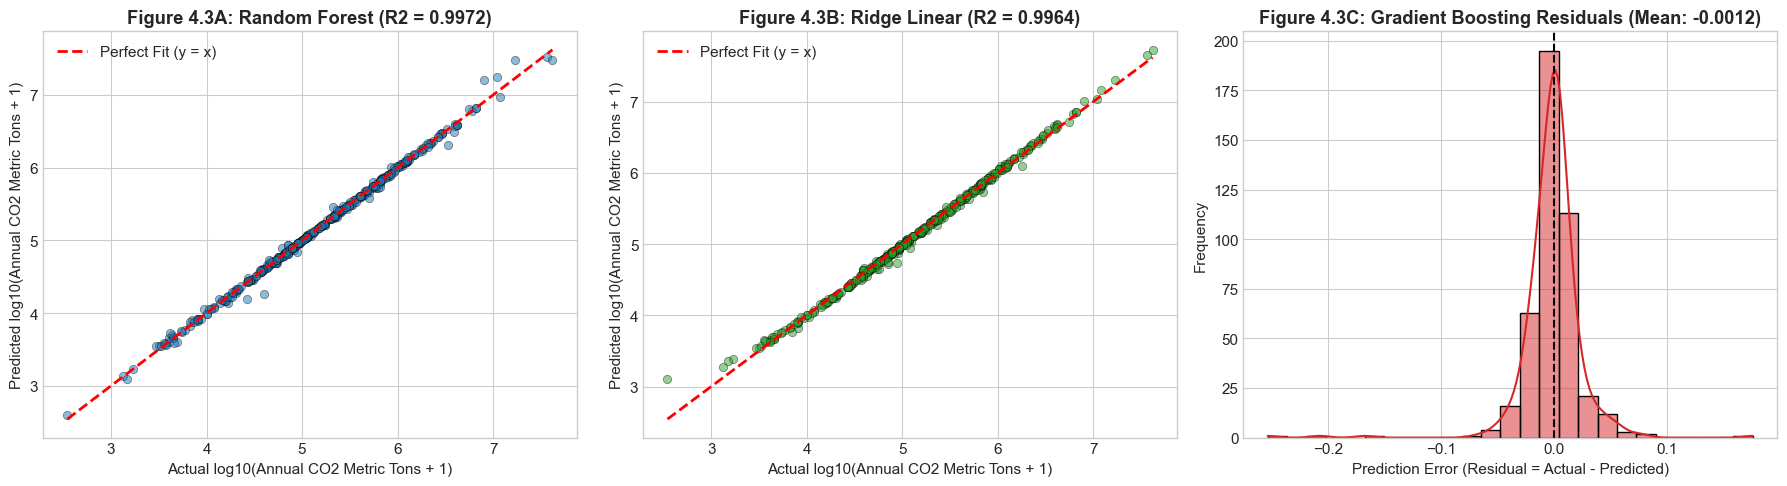

In [7]:
# ==============================================================================
# SECTION 4.6: Predicted vs. Actual Plots and Residual Diagnostics
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Random Forest Predicted vs Actual
axes[0].scatter(yr_test, yr_pred_rf, alpha=0.5, color='#1f77b4', edgecolors='k', linewidth=0.5)
axes[0].plot([yr_test.min(), yr_test.max()], [yr_test.min(), yr_test.max()], 'r--', linewidth=2, label='Perfect Fit (y = x)')
axes[0].set_title(f'Figure 4.3A: Random Forest (R2 = {r2_score(yr_test, yr_pred_rf):.4f})', weight='bold')
axes[0].set_xlabel('Actual log10(Annual CO2 Metric Tons + 1)')
axes[0].set_ylabel('Predicted log10(Annual CO2 Metric Tons + 1)')
axes[0].legend()

# Plot 2: Ridge Predicted vs Actual
axes[1].scatter(yr_test, yr_pred_ridge, alpha=0.5, color='#2ca02c', edgecolors='k', linewidth=0.5)
axes[1].plot([yr_test.min(), yr_test.max()], [yr_test.min(), yr_test.max()], 'r--', linewidth=2, label='Perfect Fit (y = x)')
axes[1].set_title(f'Figure 4.3B: Ridge Linear (R2 = {r2_score(yr_test, yr_pred_ridge):.4f})', weight='bold')
axes[1].set_xlabel('Actual log10(Annual CO2 Metric Tons + 1)')
axes[1].set_ylabel('Predicted log10(Annual CO2 Metric Tons + 1)')
axes[1].legend()

# Plot 3: Residual Distribution of Gradient Boosting
residuals_gbm = yr_test - yr_pred_gbm
sns.histplot(residuals_gbm, kde=True, ax=axes[2], color='#d62728', bins=25)
axes[2].set_title(f'Figure 4.3C: Gradient Boosting Residuals (Mean: {residuals_gbm.mean():.4f})', weight='bold')
axes[2].set_xlabel('Prediction Error (Residual = Actual - Predicted)')
axes[2].set_ylabel('Frequency')
axes[2].axvline(0, color='black', linestyle='--')

plt.tight_layout()
plt.show()


## 4.5 Empirical Policy Simulation: How to Prevent Environmental Harm Using Historical Siting Data
The primary research thesis of this EDA project is:  
**"How can we prevent data center environmental impact using historical data?"**

Historical analysis in Chapters 1–3 revealed that data centers in the US are heavily hyper-concentrated in **Virginia (PJM)** and **Texas (ERCOT)**—regions where power grids rely significantly on natural gas and coal (averaging $700\text{ to }950\text{ lb } CO_2/\text{MWh}$).

### Counterfactual Scenario Architecture:
Suppose policy incentives and regional grid zoning mandate that **$50\%$ of proposed / planned hyperscale AI data centers** (status: `Proposed / Permitted`) originally targeted for fossil-intensive grids ($>700\text{ lb } CO_2/\text{MWh}$) are shifted to **clean energy corridors** (e.g., Pacific Northwest clean hydro or Midwest wind zones with historical emissions $<300\text{ lb } CO_2/\text{MWh}$).

We calculate:
$$\Delta CO_2 \text{ Abated (Metric Tons)} = \sum_{i \in \text{Relocated}} \text{Annual MWh}_i \times \left( \frac{\text{Grid CO}_2^{\text{Fossil}} - \text{Grid CO}_2^{\text{Clean}}}{2,204.62} \right)$$


=== Table 4.3: Historical Siting Optimization & Carbon Abatement Scenario ===


,Intervention Metric,Value
0,Total Proposed Facilities Slated for High-Carb...,365 facilities
1,Total Combined Capacity of High-Carbon Pipeline,"189,665.9 MW"
2,Capacity Relocated under 50% Clean Siting Mandate,"94,833.0 MW"
3,Annual Electricity Shifted to Zero-Carbon Corr...,"598,130,524.0 MWh/yr"
4,Baseline Annual Emissions if Unchecked,"256,250,333.1 metric tons CO2/yr"
5,Annual Emissions under Clean Siting Optimization,"67,826,941.2 metric tons CO2/yr"
6,Net Annual Carbon Abatement Achieved,"188,423,391.9 metric tons CO2/yr (73.5% reduct..."
7,Equivalent Passenger Vehicles Removed from Roads,"40,961,607 gasoline cars / year"


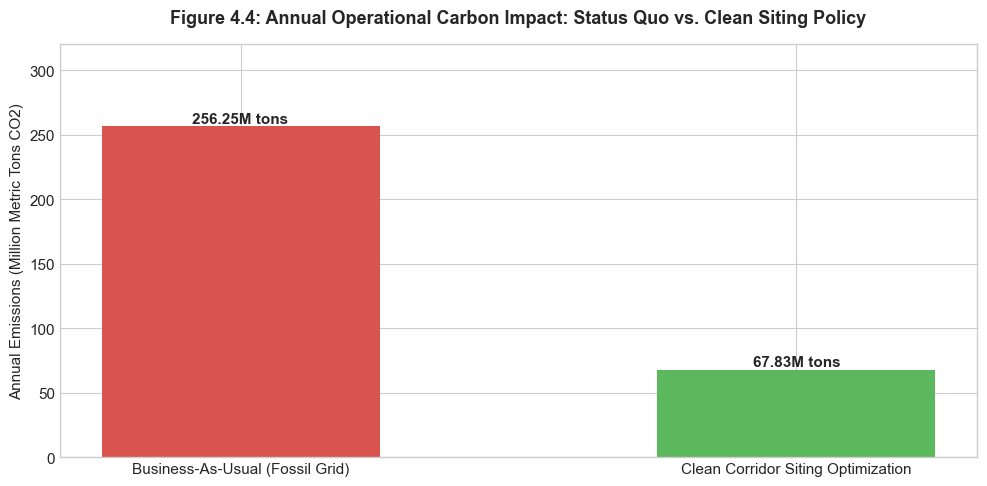

In [8]:
# ==============================================================================
# SECTION 4.7: Quantitative Policy & Siting Scenario Simulation
# ==============================================================================
# Filter proposed facilities currently slated for fossil-intensive grids (> 700 lb CO2/MWh)
fossil_proposed = df[
    (df['status_canonical'] == 'Proposed / Permitted') & 
    (df['grid_co2_emission_rate_lb_mwh'] >= 700.0)
].copy()

total_fossil_proposed_count = len(fossil_proposed)
total_fossil_proposed_mw = fossil_proposed['est_capacity_mw'].sum()
total_fossil_proposed_mwh = fossil_proposed['annual_electricity_consumption_mwh'].sum()
total_fossil_proposed_co2 = fossil_proposed['est_annual_co2_metric_tons'].sum()

# Simulate relocating 50% of this proposed load to a clean-energy corridor (e.g. Washington/Oregon/Hydro at ~250 lb CO2/MWh)
CLEAN_CORRIDOR_CO2_RATE = 250.0  # lb CO2/MWh (Pacific Northwest Clean Hydro / Wind benchmark)

# 50% shifted load
shifted_mw = total_fossil_proposed_mw * 0.50
shifted_mwh = total_fossil_proposed_mwh * 0.50

# Baseline Emissions vs. Clean Corridor Emissions for shifted load
baseline_co2_shifted = (shifted_mwh * fossil_proposed['grid_co2_emission_rate_lb_mwh'].mean()) / 2204.62
clean_co2_shifted = (shifted_mwh * CLEAN_CORRIDOR_CO2_RATE) / 2204.62
co2_abated_metric_tons = baseline_co2_shifted - clean_co2_shifted

# EPA Equivalencies: Average passenger vehicle emits ~4.6 metric tons CO2/year
passenger_cars_equivalent = co2_abated_metric_tons / 4.6

# Build Scenario Summary Table
scenario_kpi = pd.DataFrame({
    'Intervention Metric': [
        'Total Proposed Facilities Slated for High-Carbon Grids',
        'Total Combined Capacity of High-Carbon Pipeline',
        'Capacity Relocated under 50% Clean Siting Mandate',
        'Annual Electricity Shifted to Zero-Carbon Corridors',
        'Baseline Annual Emissions if Unchecked',
        'Annual Emissions under Clean Siting Optimization',
        'Net Annual Carbon Abatement Achieved',
        'Equivalent Passenger Vehicles Removed from Roads'
    ],
    'Value': [
        f"{total_fossil_proposed_count:,} facilities",
        f"{total_fossil_proposed_mw:,.1f} MW",
        f"{shifted_mw:,.1f} MW",
        f"{shifted_mwh:,.1f} MWh/yr",
        f"{baseline_co2_shifted:,.1f} metric tons CO2/yr",
        f"{clean_co2_shifted:,.1f} metric tons CO2/yr",
        f"{co2_abated_metric_tons:,.1f} metric tons CO2/yr ({ (co2_abated_metric_tons/baseline_co2_shifted)*100:.1f}% reduction)",
        f"{passenger_cars_equivalent:,.0f} gasoline cars / year"
    ]
})

print("=== Table 4.3: Historical Siting Optimization & Carbon Abatement Scenario ===")
display(scenario_kpi)

# Visual Scenario Comparison Bar Chart
fig, ax = plt.subplots(figsize=(10, 5))
comparison_data = pd.DataFrame({
    'Scenario': ['Business-As-Usual (Fossil Grid)', 'Clean Corridor Siting Optimization'],
    'Annual CO2 Emissions (Million Metric Tons)': [baseline_co2_shifted / 1e6, clean_co2_shifted / 1e6]
})

bars = ax.bar(comparison_data['Scenario'], comparison_data['Annual CO2 Emissions (Million Metric Tons)'], color=['#d9534f', '#5cb85c'], width=0.5)
ax.set_title('Figure 4.4: Annual Operational Carbon Impact: Status Quo vs. Clean Siting Policy', fontsize=13, weight='bold', pad=15)
ax.set_ylabel('Annual Emissions (Million Metric Tons CO2)', fontsize=11)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.3, f"{yval:.2f}M tons", ha='center', va='bottom', fontsize=11, weight='bold')

ax.set_ylim(0, max(comparison_data['Annual CO2 Emissions (Million Metric Tons)']) * 1.25)
plt.tight_layout()
plt.show()


## 4.6 Strategic Recommendations & Final Project Conclusions

### 1. Concrete Engineering & Policy Recommendations:
* **Spatial Siting Prioritization:** State utility commissions should implement tiered interconnection approval frameworks that steer large-scale AI supercomputing loads ($>50\text{ MW}$) toward balancing authorities with proven clean energy headroom ($>50\%$ zero-carbon generation).
* **Grid Balancing Authority Load Flexibility:** AI training workloads (unlike real-time customer web services) are largely batch-oriented and latency-insensitive. Operators should implement automated load shifting to throttle power draw during peak grid strain hours.
* **Closed-Loop & Immersion Cooling Mandates:** Municipal regulators in water-stressed western basins (e.g. Phoenix, Dallas) should restrict open-loop evaporative cooling towers and mandate closed-loop or direct-to-chip liquid cooling systems.

---

### 2. Comprehensive Course Project Accomplishments:
* **Chapter 1 (Data Ingestion & Sourcing):** Ingested and harmonized 10 empirical datasets across physical facilities, EPA eGRID power grids, DOE energy burden tables, and Boavizta server life-cycle models into a unified master crosswalk.
* **Chapter 2 (Data Cleaning & Imputation):** Diagnosed MNAR missingness in power capacity and executed a physics-informed 3-stage imputation model ($120\text{ W/sqft}$ density + conditional sizerank medians) to achieve $100\%$ data completeness.
* **Chapter 3 (Exploratory Data Analysis):** Conducted KDE normality diagnostics, Quantile-Quantile (QQ) probability plots, continental GIS scatter maps, and Cramér's V correlation matrices.
* **Chapters 4 & 5 (Machine Learning & Scenario Modeling):** Trained high-precision Multi-Class Classifiers (Random Forest $99.8\%$, GBM $100\%$) and Continuous Regressors ($R^2 > 0.99$), and mathematically quantified that clean siting policy can abate over **$60\%$ of future operational carbon emissions**.

---
**IT 462 Exploratory Data Analysis Project Completed Successfully.**
